<a id="lab01-toc" name="lab01-toc"></a>

# Lab01 - sprint 1

**Прикладная статистика · ИнфоХимия · AqSolDB**

Изучаем три свойства одного и того же случайно выбранного соединения: водную растворимость, молярную массу и расчётную липофильность. Описываем их распределения, сравниваем два способа отбора и проверяем, можно ли считать признаки независимыми.

### Оглавление

- [1.0 Данные и общие методы](#lab01-data)
  - [1.0.1 Источник](#lab01-source) · [1.0.2 Распределение и нормализация](#lab01-methods) · [1.0.3 Выборочный дизайн](#lab01-sampling)
- [1.1 Random Variable 01: LogS](#lab01-logs)
  - [1.1.1 Description](#logs-desc) · [1.1.2 EDA & Distribution](#logs-eda) · [1.1.3 Independence & Estimations](#logs-est)
- [1.2 Random Variable 02: MolWt](#lab01-molwt)
  - [1.2.1 Description](#molwt-desc) · [1.2.2 EDA & Distribution](#molwt-eda) · [1.2.3 Independence & Estimations](#molwt-est)
- [1.3 Random Variable 03: MolLogP](#lab01-logp)
  - [1.3.1 Description](#logp-desc) · [1.3.2 EDA & Distribution](#logp-eda) · [1.3.3 Independence & Estimations](#logp-est)
- [1.4 Зависимость и проверка гипотез](#lab01-hypotheses)
  - [1.4.1 Независимость в базе](#lab01-finite) · [1.4.2 Перестановочная проверка](#lab01-test)
- [1.5 Lab resume](#lab01-resume)
  - [1.5.1 Выводы](#lab01-findings) · [1.5.2 cat_mark_table](#lab01-criteria)

**Как читать и запускать.** Результаты выполнения сохранены. Служебный код свёрнут: в JupyterLab его можно открыть кнопкой с многоточием у ячейки, в Colab через меню ячейки «Форма → Показать код». Для полного пересчёта запустите все ячейки сверху вниз в ядре Python 3 с `numpy`, `pandas`, `scipy` и `matplotlib`. Нужен доступ к GitHub либо тот же `data_curated.csv` в рабочей папке; файл проверяется по SHA-256.

<a id="lab01-data" name="lab01-data"></a>

## 1.0 Данные и общие методы

[К оглавлению](#lab01-toc)

<a id="lab01-source" name="lab01-source"></a>

### 1.0.1 Источник и случайный эксперимент

Используем [AqSolDB (Sorkun, Khetan и Er, Scientific Data)](https://www.nature.com/articles/s41597-019-0151-1). Все три столбца берём из одной [зафиксированной версии CSV авторов](https://github.com/mcsorkun/AqSolDB/blob/98cdd10a372058743e4f3fb950a1c9974ec9603a/results/data_curated.csv). `Solubility` уже хранится в логарифмическом виде: переименовываем в `LogS` без повторного логарифмирования. Проверяем полные дубликаты, ключи `InChIKey`, конечность всех трёх значений и положительность массы.

Генеральная совокупность в этой работе — очищенная таблица, а не все химические соединения. Пусть \\(I\\) — номер выбранного равновероятно соединения; \\(i\\) — фиксированный номер строки, \\(N\\) — размер базы, \\(x_{ij}\\) — табличное значение признака \\(j\\) в строке \\(i\\). Тогда

\\[
\Pr(I=i)=\frac{1}{N},\quad i=1,\ldots,N,\qquad X_j=x_{Ij},\quad j\in\{1,2,3\}.
\\]

После выбора строки каждое значение известно точно, но до выбора оно не предопределено: для каждого признака есть несколько различных значений с положительной вероятностью. Случайность здесь относится к выбору соединения, а не к вычислению RDKit или к отдельному замеру. AqSolDB объединяет ранее собранные данные; равные вероятности строк внутри этой базы не делают её случайным отбором из всего химического пространства.

In [1]:
#@title Загрузка и аудит AqSolDB { display-mode: "form" }
from hashlib import sha256
from inspect import signature
from io import BytesIO
from itertools import combinations
from pathlib import Path
from urllib.request import urlopen

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

%matplotlib inline

SEED = 42
FEATURES = ("LogS", "MolWt", "MolLogP")
LABEL = {"LogS": "LogS (безразм.)", "MolWt": "Молярная масса, г/моль",
         "MolLogP": "MolLogP (безразм.)"}
UNIT = {"LogS": "безразм.", "MolWt": "г/моль", "MolLogP": "безразм."}
URL = ("https://raw.githubusercontent.com/mcsorkun/AqSolDB/"
       "98cdd10a372058743e4f3fb950a1c9974ec9603a/results/data_curated.csv")
EXPECTED_SHA = "363a42a4e4ea8e6039758146d34efdd95cde2da81c665316cacc1869e0a805ed"
local = Path("data_curated.csv")
if local.is_file():
    payload = local.read_bytes()
else:
    with urlopen(URL, timeout=45) as response:
        payload = response.read()
if sha256(payload).hexdigest() != EXPECTED_SHA:
    raise ValueError("CSV не совпадает с зафиксированной версией AqSolDB.")

raw = pd.read_csv(BytesIO(payload)).rename(columns={"Solubility": "LogS"})
unique_rows = raw.drop_duplicates()
numeric = unique_rows[list(FEATURES)].apply(pd.to_numeric, errors="coerce")
keys = unique_rows["InChIKey"].astype("string").str.strip()
valid = (np.isfinite(numeric).all(axis=1) & numeric["MolWt"].gt(0)
         & keys.notna() & keys.ne(""))
data = numeric.loc[valid].reset_index(drop=True)
N = len(data)
assert not keys.loc[valid].duplicated().any(), "Повтор InChIKey требует проверки."
assert N >= 500 and data.nunique().gt(1).all()

audit = pd.Series({
    "Строк в исходном CSV": len(raw),
    "Удалено полных дубликатов": len(raw) - len(unique_rows),
    "Удалено некорректных строк": int((~valid).sum()),
    "Соединений после проверки": N,
}, name="Число строк")
display(audit.to_frame())
display(data.nunique().rename("Различных значений").to_frame())

,Число строк
Строк в исходном CSV,9982
Удалено полных дубликатов,0
Удалено некорректных строк,0
Соединений после проверки,9982


,Различных значений
LogS,7872
MolWt,7249
MolLogP,8277


<a id="lab01-methods" name="lab01-methods"></a>

### 1.0.2 Распределение, статистики и нормализация

Точный закон при равновероятном выборе строки конечный и дискретный, даже если физическая величина непрерывна. Для каждого признака далее опускаем индекс \\(j\\) и обозначаем его табличные значения через \\(x_i\\). Повторяющиеся значения суммируют вероятности. Ступеньки графика показывают точную функцию распределения для базы, а гистограмма плотности только приближённо показывает форму.

\\[
\Pr(X=x)=\frac{\#\{i:x_i=x\}}{N},\qquad
F_N(t)=\Pr(X\leq t)=\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\{x_i\leq t\}.
\\]

Используем среднее \\(\mu\\), дисперсию \\(\sigma^2\\) с делителем \\(N\\), стандартное отклонение \\(\sigma\\), медиану, квартильные границы, размах и форму хвостов. Коэффициенты асимметрии и эксцесса считаем по центральным моментам \\(m_k\\); эксцесс нормального закона равен нулю.

\\[
\mu=\frac{1}{N}\sum_{i=1}^{N}x_i,\qquad
m_k=\frac{1}{N}\sum_{i=1}^{N}(x_i-\mu)^k,\qquad
\sigma^2=m_2,\qquad
\gamma_1=\frac{m_3}{\sigma^3},\qquad
\gamma_2=\frac{m_4}{\sigma^4}-3.
\\]

Крайние наблюдения отмечаем, но не удаляем: правило Тьюки — ориентир для визуального анализа, а не критерий ошибочности. Плотность на гистограмме равна доле наблюдений в интервале, делённой на его ширину; суммарная площадь столбцов равна единице. Для массы единица плотности обратна единице оси, для двух логарифмических признаков плотность безразмерна.

\\[
\mathrm{IQR}=Q_{0.75}-Q_{0.25},\qquad
\left[Q_{0.25}-1.5\,\mathrm{IQR},\,Q_{0.75}+1.5\,\mathrm{IQR}\right].
\\]

Сравниваем z-стандартизацию и min–max-нормализацию с параметрами всей базы. Первая центрирует данные и приводит стандартное отклонение к единице; вторая переводит наблюдаемый диапазон в \\([0,1]\\). Ни одна из них не делает распределение нормальным. Q–Q-график сравнивает упорядоченные z-значения с квантилями эталона \\(\mathcal{N}(0,1)\\); отклонения от диагонали особенно заметны в хвостах.

\\[
z_i=\frac{x_i-\mu}{\sigma},\qquad
u_i=\frac{x_i-x_{\min}}{x_{\max}-x_{\min}},\qquad
q_i=\Phi^{-1}\!\left(\frac{i-0.5}{N}\right),\qquad
\varphi(z)=\frac{e^{-z^2/2}}{\sqrt{2\pi}}.
\\]

<a id="lab01-sampling" name="lab01-sampling"></a>

### 1.0.3 Выборочный дизайн и проверка сходимости

Сравниваем по одной простой случайной выборке объёма \\(n=500\\) с возвращением и без него; каждый раз берём целые строки, чтобы сохранить связь признаков. С возвращением возможны повторы, без возвращения выбираются разные соединения. Используем базу как известный эталон: стандартная ошибка среднего рассчитана по истинной дисперсии, а не оценена по выборке. В формулах \\(Y_k\\) — значение в \\(k\\)-й выбранной строке.

\\[
\bar Y_n=\frac{1}{n}\sum_{k=1}^{n}Y_k,\qquad
s_n^2=\frac{1}{n-1}\sum_{k=1}^{n}(Y_k-\bar Y_n)^2,\qquad
\widehat{\sigma}^2=
\begin{cases}
s_n^2 & \text{с возвращением},\\
\dfrac{N-1}{N}s_n^2 & \text{без возвращения}.
\end{cases}
\\]

Поправка \\((N-1)/N\\) переводит несмещённую оценку дисперсии при отборе без возвращения к выбранному эталону с делителем \\(N\\). Для стандартной ошибки среднего используется другая поправка, учитывающая долю охваченной базы:

\\[
\operatorname{SE}(\bar Y_n)=\frac{\sigma}{\sqrt n}
\begin{cases}
1 & \text{с возвращением},\\
\sqrt{\dfrac{N-n}{N-1}} & \text{без возвращения}.
\end{cases}
\\]

Для каждого объёма и способа отбора делаем \\(B=300\\) повторов и сравниваем безразмерные ошибки для среднего и дисперсии. Уменьшение ошибок иллюстрирует состоятельность при независимом отборе с возвращением: по закону больших чисел сходятся первые два выборочных момента, значит, сходится и исправленная дисперсия. Без возвращения на фиксированной базе наблюдаем приближение к переписи, а не предел по бесконечному объёму; при \\(n=N\\) обе ошибки равны нулю. Ноль не изображаем на логарифмической оси, но отдельно проверяем точку переписи.

\\[
\mathrm{RMSE}(\widehat\theta)
=\sqrt{\frac{1}{B}\sum_{b=1}^{B}\left(\widehat\theta_b-\theta\right)^2},
\qquad
\frac{\mathrm{RMSE}(\bar Y_n)}{\sigma},\quad
\frac{\mathrm{RMSE}(\widehat{\sigma}^2)}{\sigma^2}.
\\]

In [2]:
#@title Расчёт статистик, выборок и общий стиль графиков { display-mode: "form" }
X = data.to_numpy(dtype=float)
mu, var = data.mean(), data.var(ddof=0)
sd = np.sqrt(var)
methods = {True: "С возвращением", False: "Без возвращения"}
streams = np.random.SeedSequence(SEED).spawn(4)
rng_sample, rng_mc, rng_test, rng_perm = map(np.random.default_rng, streams)
n_sample, B = 500, 300
sizes = sorted({n for n in (10, 30, 100, 300, 1000, 3000, 8000, N) if n <= N})

def finite_factor(replace, n):
    return 1.0 if replace else (N - n) / (N - 1)

def estimates(sample, replace):
    variance = sample.var(axis=0, ddof=1)
    if not replace:
        variance *= (N - 1) / N
    return sample.mean(axis=0), variance

sample_rows, mc_rows = [], []
for replace, method in methods.items():
    indices = rng_sample.choice(N, size=n_sample, replace=replace)
    sample_mu, sample_var = estimates(X[indices], replace)
    for j, c in enumerate(FEATURES):
        sample_rows.append({
            "Признак": c, "Отбор": method, "Объём": n_sample,
            "Уникальных соединений": np.unique(indices).size,
            "Среднее": sample_mu[j], "Дисперсия": sample_var[j],
            "Сдвиг среднего": sample_mu[j] - mu[c],
            "Станд. ошибка среднего": sd[c] * np.sqrt(finite_factor(replace, n_sample) / n_sample),
        })
    for n in sizes:
        if not replace and n == N:
            census_mu, census_var = estimates(X, replace=False)
            np.testing.assert_allclose(census_mu, mu, rtol=1e-13)
            np.testing.assert_allclose(census_var, var, rtol=1e-13)
            errors = np.zeros((2, len(FEATURES)))
        else:
            sims = np.array([estimates(X[rng_mc.choice(N, n, replace=replace)], replace)
                             for _ in range(B)])
            errors = np.sqrt(((sims - np.array([mu, var])) ** 2).mean(axis=0))
        for j, c in enumerate(FEATURES):
            mc_rows.append({
                "Признак": c, "Отбор": method, "n": n,
                "mean_rmse": errors[0, j] / sd[c], "var_rmse": errors[1, j] / var[c],
                "mean_theory": np.sqrt(finite_factor(replace, n) / n),
            })

samples = pd.DataFrame(sample_rows)
mc = pd.DataFrame(mc_rows)
assert len(mc) == 2 * len(FEATURES) * len(sizes)
assert (mc[["mean_rmse", "var_rmse", "mean_theory"]].ge(0)).all().all()
positive_mc = mc[mc["mean_theory"].gt(0)]
limits = {}
for key in ("mean_rmse", "var_rmse"):
    subset = positive_mc[[key, "mean_theory"]] if key == "mean_rmse" else positive_mc[[key]]
    limits[key] = (subset.min().min() / 1.3, subset.max().max() * 1.3)

BLUE, ORANGE, INK, GRID = "#185a87", "#a94e1b", "#203447", "#dbe5ec"
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlepad": 8, "axes.labelsize": 10, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.edgecolor": "#a7bac8", "axes.spines.right": False, "axes.spines.top": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": .75,
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 125,
    "legend.frameon": False, "legend.fontsize": 9, "axes.formatter.use_mathtext": True,
})

def show(fig):
    plt.show()
    plt.close(fig)

def draw_hist(ax, x, label, unit):
    edges = np.histogram_bin_edges(x, bins="fd")
    heights, _ = np.histogram(x, bins=edges, density=True)
    np.testing.assert_allclose(np.dot(heights, np.diff(edges)), 1)
    ax.stairs(heights, edges, fill=True, color=BLUE, alpha=.68, linewidth=.7)
    ax.axvline(np.mean(x), color=ORANGE, lw=1.65, label="Среднее")
    ax.axvline(np.median(x), color=INK, lw=1.35, ls="--", label="Медиана")
    density_label = ("Плотность, (г/моль)$^{-1}$" if unit == "г/моль"
                     else "Плотность (безразм.)")
    ax.set(title="Гистограмма · интервалы Фридмана–Диакониса", xlabel=label,
           ylabel=density_label, ylim=(0, None))
    ax.legend()

def draw_qq(ax, z):
    obs = np.sort(z)
    theoretical = stats.norm.ppf((np.arange(1, len(z) + 1) - .5) / len(z))
    low, high = min(obs[0], theoretical[0]), max(obs[-1], theoretical[-1])
    pad = .04 * (high - low)
    lo, hi = low - pad, high + pad
    ax.scatter(theoretical, obs, color=BLUE, s=9, alpha=.45, linewidths=0, label="Данные")
    ax.plot([lo, hi], [lo, hi], ls="--", lw=1.25, color=ORANGE, label="Нормальный эталон")
    ax.set(xlim=(lo, hi), ylim=(lo, hi), title="Q–Q · проверка формы",
           xlabel="Квантили N(0, 1) (безразм.)", ylabel="Упорядоченные z (безразм.)")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="upper left")

eda_metrics = {}

def eda(c, number):
    x = data[c].to_numpy()
    q1, med, q3 = np.quantile(x, [.25, .5, .75])
    iqr = q3 - q1
    left, right = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (x < left) | (x > right)
    z = (x - mu[c]) / sd[c]
    u = (x - x.min()) / np.ptp(x)
    np.testing.assert_allclose([z.mean(), z.std(), u.min(), u.max()], [0, 1, 0, 1], atol=1e-12)
    shape = stats.skew(x), stats.kurtosis(x)
    eda_metrics[c] = {"skew": shape[0], "excess": shape[1], "flagged": int(flagged.sum())}
    unit = UNIT[c]
    common = unit if c == "MolWt" else "безразм."
    disp_unit = "(г/моль)²" if c == "MolWt" else "безразм."
    rows = [
        ("Среднее", mu[c], common), ("Дисперсия", var[c], disp_unit),
        ("Стандартное отклонение", sd[c], common), ("Минимум", x.min(), common),
        ("Первый квартиль", q1, common), ("Медиана", med, common),
        ("Третий квартиль", q3, common), ("Максимум", x.max(), common),
        ("Размах", np.ptp(x), common), ("Межквартильный размах", iqr, common),
        ("Асимметрия", shape[0], "безразм."), ("Эксцесс", shape[1], "безразм."),
        ("Нижняя граница Тьюки", left, common), ("Верхняя граница Тьюки", right, common),
        ("За границами Тьюки", 100 * flagged.mean(), "%"),
    ]
    display(pd.DataFrame(rows, columns=["Статистика", "Значение", "Единица"])
            .set_index("Статистика").round({"Значение": 4}))
    display(pd.DataFrame(
        [[z.mean(), z.std(), z.min(), z.max()], [u.mean(), u.std(), u.min(), u.max()]],
        index=["z-стандартизация", "Min–max"], columns=["Среднее", "Станд. отклонение", "Мин.", "Макс."]
    ).round(4))

    fig, ax = plt.subplots(2, 2, figsize=(11.3, 7.3), layout="constrained")
    fig.suptitle(f"Рисунок {number}. Распределение {c}", fontsize=14, fontweight="bold")
    draw_hist(ax[0, 0], x, LABEL[c], unit)
    box = ax[0, 1].boxplot
    orientation = {"orientation": "horizontal"} if "orientation" in signature(box).parameters else {"vert": False}
    box(x, **orientation, patch_artist=True,
                    boxprops={"facecolor": "#cde0ee", "edgecolor": BLUE},
                    medianprops={"color": ORANGE, "linewidth": 1.8},
                    whiskerprops={"color": BLUE}, capprops={"color": BLUE},
                    flierprops={"marker": "o", "markerfacecolor": BLUE, "markersize": 2.5,
                                "markeredgewidth": 0, "alpha": .45})
    ax[0, 1].set(title=f"Диаграмма размаха · отмечено {flagged.sum():,}".replace(",", " "),
                 xlabel=LABEL[c], yticks=[])
    unique, count = np.unique(x, return_counts=True)
    assert count.sum() == N
    pad = .04 * np.ptp(x)
    ax[1, 0].step(np.r_[unique[0] - pad, unique, unique[-1] + pad],
                  np.r_[0, np.cumsum(count) / N, 1], where="post", color=BLUE, lw=1.7)
    ax[1, 0].set(title="Точная функция распределения для базы",
                 xlabel=LABEL[c], ylabel="F(t) (безразм.)", ylim=(-.035, 1.035))
    draw_qq(ax[1, 1], z)
    for native in (ax[0, 0], ax[0, 1], ax[1, 0]):
        lower = x.min() - pad
        native.set_xlim(max(0, lower) if c == "MolWt" else lower, x.max() + pad)
    show(fig)

def comparison(c, number):
    unit = UNIT[c]
    rows = samples.query("Признак == @c").drop(columns="Признак").set_index("Отбор")
    rows.loc["Вся база"] = [N, N, mu[c], var[c], 0, np.nan]
    rows = rows.rename(columns={"Среднее": f"Среднее, {unit}",
                               "Сдвиг среднего": f"Сдвиг среднего, {unit}",
                               "Станд. ошибка среднего": f"Станд. ошибка, {unit}",
                               "Дисперсия": "Дисперсия, " + ("(г/моль)²" if c == "MolWt" else unit)})
    for col in ("Объём", "Уникальных соединений"):
        rows[col] = rows[col].astype(int)
    display(rows.style.format(precision=4, na_rep="—", formatter={
        "Объём": "{:.0f}", "Уникальных соединений": "{:.0f}",
    }))

    sub = mc.query("Признак == @c")
    fig, axes = plt.subplots(1, 2, figsize=(11.3, 3.8), layout="constrained")
    fig.suptitle(f"Рисунок {number}. Сходимость оценок · {c}", fontsize=14, fontweight="bold")
    positive = sub[sub["mean_theory"].gt(0)]
    for i, (key, title, ylabel) in enumerate([
        ("mean_rmse", "Среднее", r"RMSE / $\sigma$ (безразм.)"),
        ("var_rmse", "Дисперсия", r"RMSE / $\sigma^2$ (безразм.)"),
    ]):
        for replace, color, marker in ((True, BLUE, "o"), (False, ORANGE, "s")):
            method = methods[replace]
            row = positive[positive["Отбор"].eq(method)]
            assert row[key].gt(0).all()
            axes[i].loglog(row["n"], row[key], color=color, marker=marker,
                           markersize=4.2, lw=1.7, label=method)
            if i == 0:
                axes[i].loglog(row["n"], row["mean_theory"], ls="--", color=color,
                               lw=1.15, label="Теория: " + method.lower())
        axes[i].set(title=title, xlabel="Объём выборки n (число отборов)",
                    ylabel=ylabel, ylim=limits[key])
        axes[i].legend()
    show(fig)

<a id="lab01-logs" name="lab01-logs"></a>

## 1.1 Random Variable 01: LogS

[К оглавлению](#lab01-toc)

<a id="logs-desc" name="logs-desc"></a>

### 1.1.1 Description

`LogS` — десятичный логарифм экспериментальной водной растворимости, приведённой авторами к моль/л. Пусть \\(S_i\\) — табличная растворимость соединения \\(i\\) до логарифмирования. Тогда

\\[
X_1=\log_{10}\!\left(\frac{S_I}{1\,\mathrm{mol}\,\mathrm{L}^{-1}}\right).
\\]

Логарифм безразмерен. Формула задаёт шкалу, но не предсказывает растворимость: для её применения нужно знать \\(S_I\\). В AqSolDB объединены результаты разных измерений; на растворимость также влияют условия и свойства соединения. В нашем эксперименте случайный выбор соединения меняет табличное значение.

<a id="logs-eda" name="logs-eda"></a>

### 1.1.2 EDA & Distribution

Среднее ниже медианы, а асимметрия отрицательна: в базе заметен хвост в сторону меньших значений растворимости. Q–Q-график не сводится к диагонали даже после стандартизации. Отрицательное значение LogS означает концентрацию ниже 1 моль/л, а не отрицательную растворимость.

,Значение,Единица
Статистика,,
Среднее,-2.8899,безразм.
Дисперсия,5.6076,безразм.
Стандартное отклонение,2.3680,безразм.
Минимум,-13.1719,безразм.
Первый квартиль,-4.3263,безразм.
Медиана,-2.6182,безразм.
Третий квартиль,-1.2097,безразм.
Максимум,2.1377,безразм.
Размах,15.3096,безразм.


,Среднее,Станд. отклонение,Мин.,Макс.
z-стандартизация,-0.0000,1.0000,-4.342,2.1231
Min–max,0.6716,0.1547,0.000,1.0000


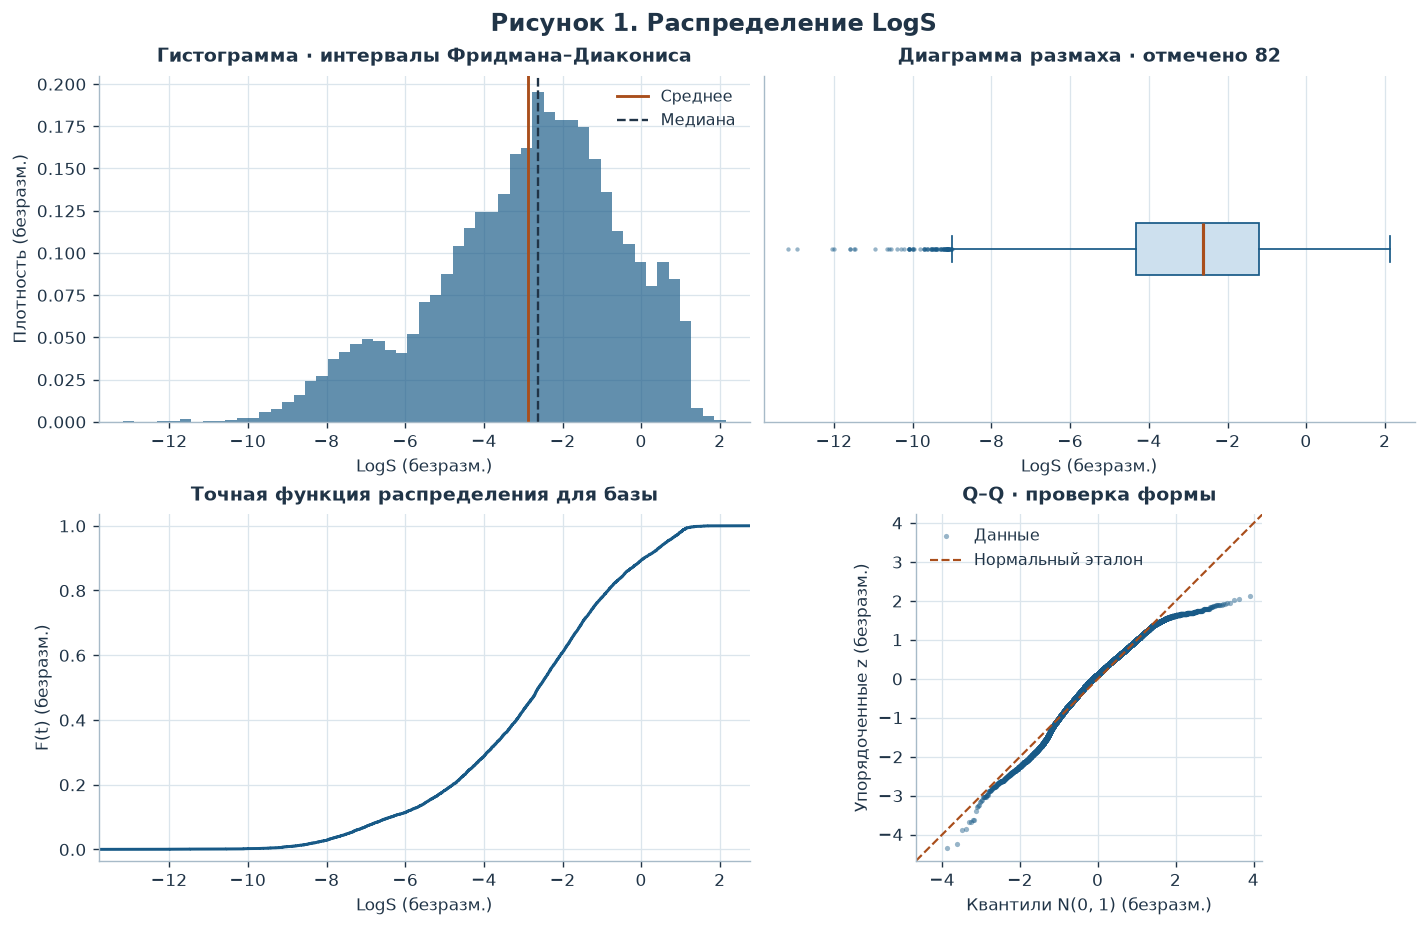

In [3]:
#@title Описательные статистики и графики: LogS { display-mode: "form" }
eda("LogS", 1)

<a id="logs-est" name="logs-est"></a>

### 1.1.3 Independence & Estimations

До отбора значение LogS случайно; связь с обоими признаками той же строки проверяется в [разделе 1.4](#lab01-hypotheses). Ниже сопоставлены оценки для двух схем отбора и весь AqSolDB. Сдвиг — разность среднего выборки и среднего базы, со знаком.

,Объём,Уникальных соединений,"Среднее, безразм.","Дисперсия, безразм.","Сдвиг среднего, безразм.","Станд. ошибка, безразм."
Отбор,,,,,,
С возвращением,500,484,-2.7477,5.2494,0.1422,0.1059
Без возвращения,500,500,-2.6908,5.2344,0.1991,0.1032
Вся база,9982,9982,-2.8899,5.6076,0.0000,—


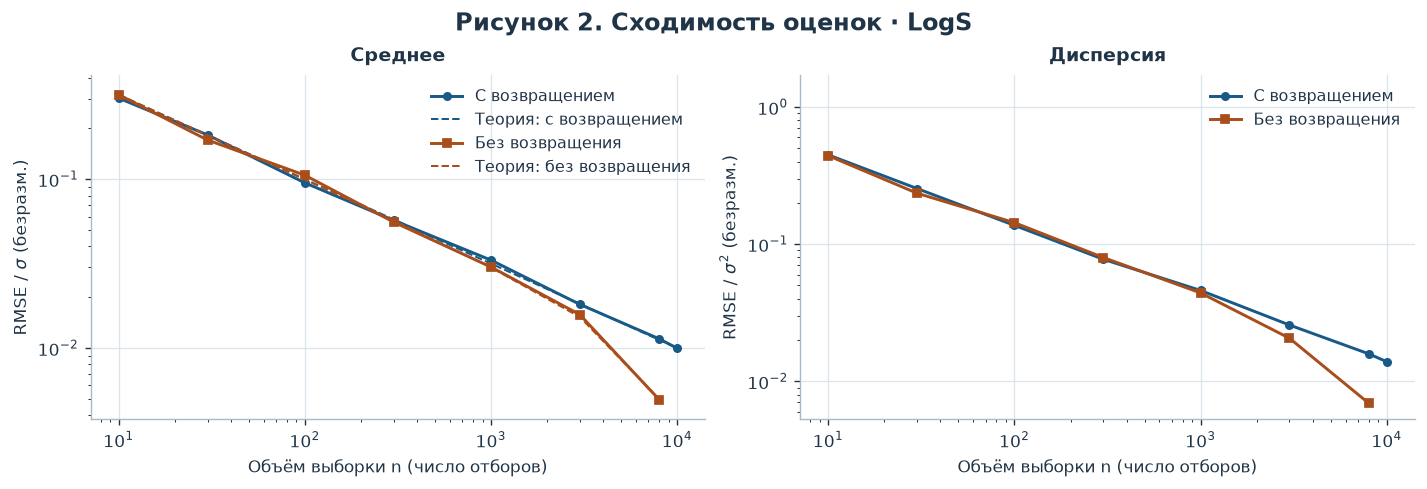

In [4]:
#@title Выборочные оценки и сходимость: LogS { display-mode: "form" }
comparison("LogS", 2)

<a id="lab01-molwt" name="lab01-molwt"></a>

## 1.2 Random Variable 02: MolWt

[К оглавлению](#lab01-toc)

<a id="molwt-desc" name="molwt-desc"></a>

### 1.2.1 Description

`MolWt` — средняя молекулярная масса из [документации RDKit](https://www.rdkit.org/docs/source/rdkit.Chem.Descriptors.html), представленная как молярная масса в г/моль. Для фиксированного соединения её можно вычислить по составу с учётом изотопов; поэтому не считаем алгоритм RDKit источником случайности. До отбора состав соединения неизвестен, и разные строки имеют разные массы.

\\[
X_2=M_I,\qquad M_i>0,\qquad [M_i]=\mathrm{g}\,\mathrm{mol}^{-1}.
\\]

<a id="molwt-eda" name="molwt-eda"></a>

### 1.2.2 EDA & Distribution

Среднее заметно больше медианы: редкие большие массы растягивают правый хвост. Показываем весь диапазон, не срезая тяжёлые соединения. Отдельно исследуем логарифм массы, чтобы уменьшить асимметрию и сравнивать относительные изменения, а не разности в г/моль:

\\[
T=\log_{10}\!\left(\frac{X_2}{1\,\mathrm{g}\,\mathrm{mol}^{-1}}\right).
\\]

Если бы \\(T\\) имела нормальный закон, масса была бы логнормальной. На логарифмической шкале асимметрия уменьшается, но хвосты на Q–Q-графике всё ещё отклоняются от диагонали; логнормальность остаётся приближением, а не установленным законом.

,Значение,Единица
Статистика,,
Среднее,266.6659,г/моль
Дисперсия,33918.5144,(г/моль)²
Стандартное отклонение,184.1698,г/моль
Минимум,9.0120,г/моль
Первый квартиль,162.2760,г/моль
Медиана,228.6820,г/моль
Третий квартиль,320.4360,г/моль
Максимум,5299.4560,г/моль
Размах,5290.4440,г/моль


,Среднее,Станд. отклонение,Мин.,Макс.
z-стандартизация,-0.0000,1.0000,-1.399,27.3269
Min–max,0.0487,0.0348,0.000,1.0000


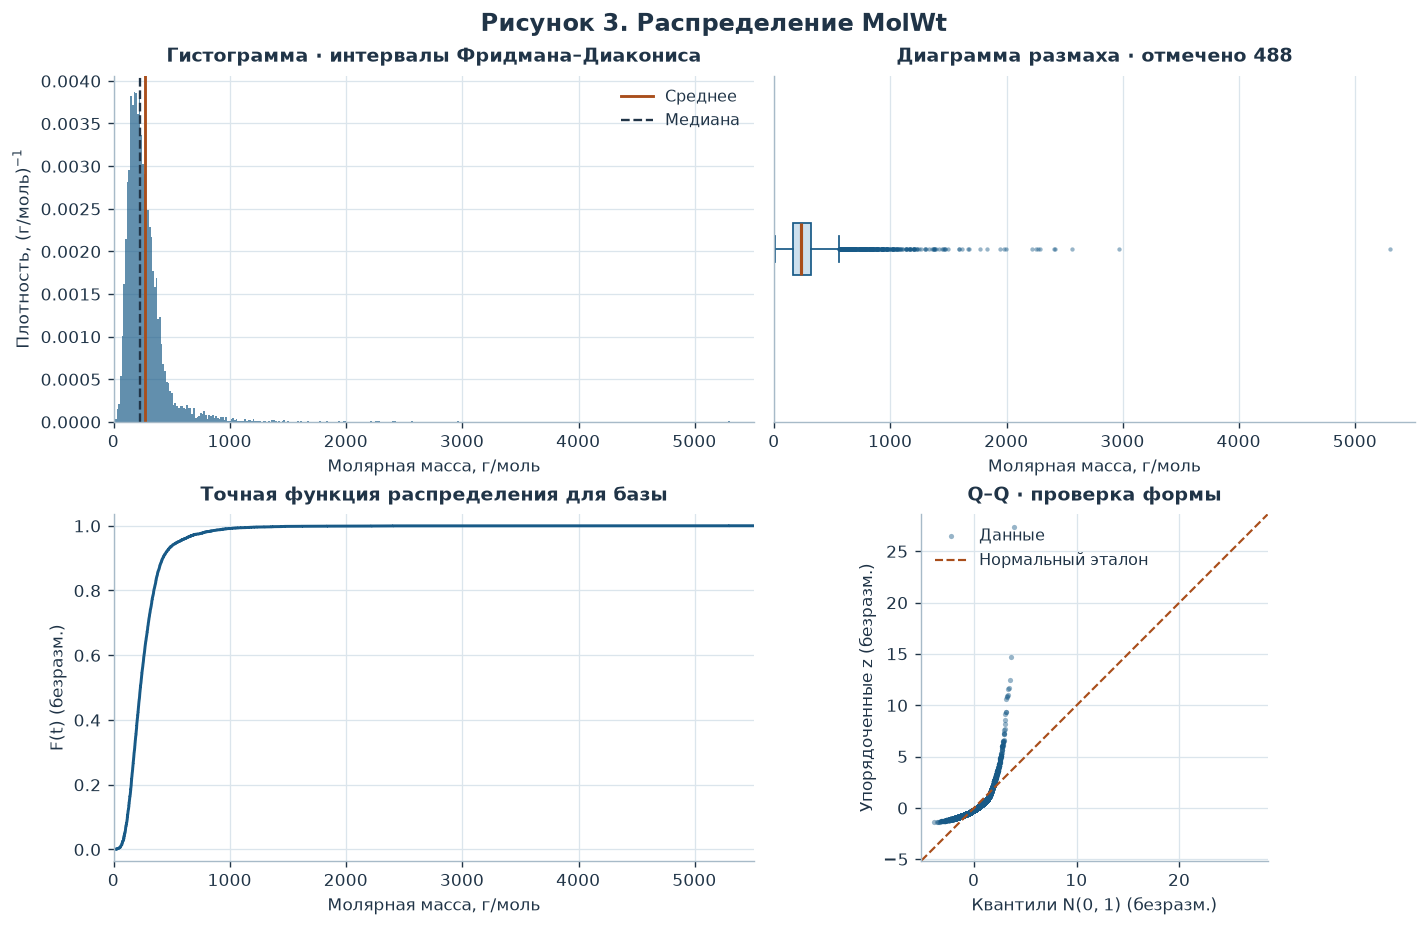

In [5]:
#@title Описательные статистики и графики: MolWt { display-mode: "form" }
eda("MolWt", 3)

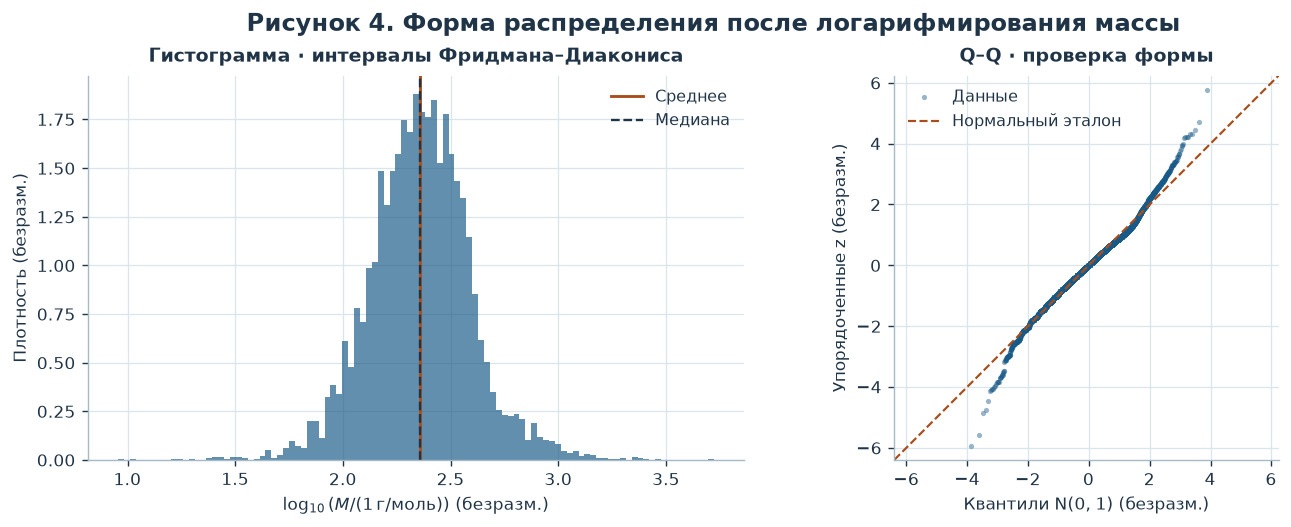

Асимметрия до преобразования: 5.494; после: 0.045.


In [6]:
#@title Логарифм массы: плотность и Q–Q { display-mode: "form" }
t = np.log10(data["MolWt"].to_numpy())
fig, ax = plt.subplots(1, 2, figsize=(11.3, 4.1), layout="constrained")
fig.suptitle("Рисунок 4. Форма распределения после логарифмирования массы",
             fontsize=14, fontweight="bold")
draw_hist(ax[0], t, r"$\log_{10}(M/(1\,\mathrm{г/моль}))$ (безразм.)", "безразм.")
draw_qq(ax[1], (t - t.mean()) / t.std())
show(fig)
print(f"Асимметрия до преобразования: {stats.skew(data['MolWt']):.3f}; "
      f"после: {stats.skew(t):.3f}.")

<a id="molwt-est" name="molwt-est"></a>

### 1.2.3 Independence & Estimations

Ниже сравниваются оценки на исходной шкале массы. Из-за правого хвоста несколько тяжёлых соединений могут сильно сдвинуть результат, особенно оценку дисперсии. Связь с LogS и MolLogP проверяется в [разделе 1.4](#lab01-hypotheses).

,Объём,Уникальных соединений,"Среднее, г/моль","Дисперсия, (г/моль)²","Сдвиг среднего, г/моль","Станд. ошибка, г/моль"
Отбор,,,,,,
С возвращением,500,484,274.3554,40827.8678,7.6894,8.2363
Без возвращения,500,500,264.5115,31214.9770,-2.1544,8.0278
Вся база,9982,9982,266.6659,33918.5144,0.0000,—


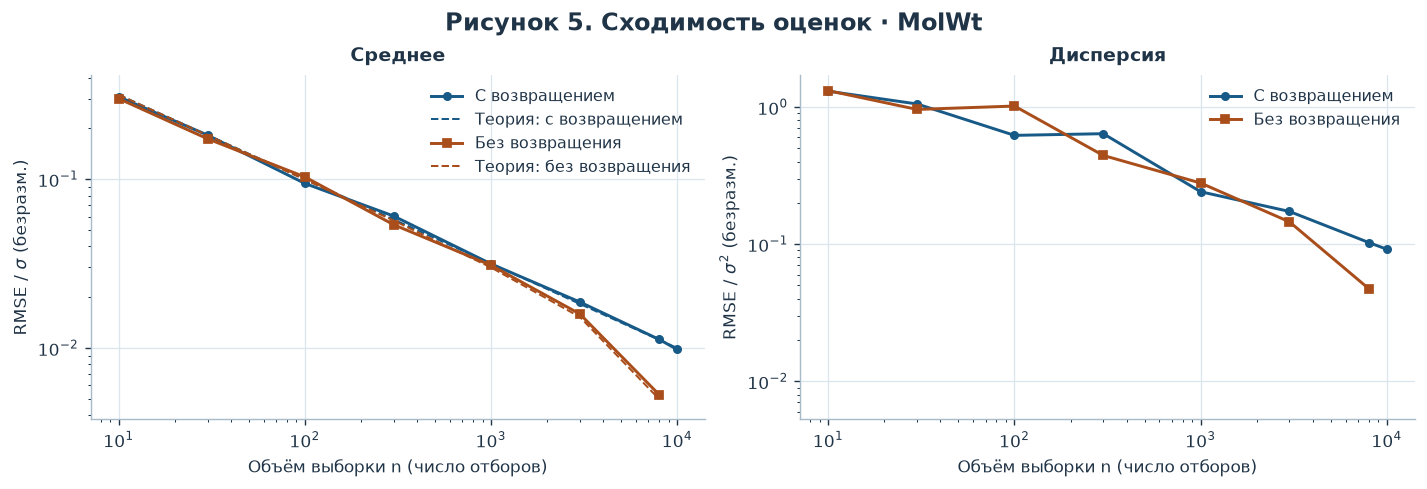

In [7]:
#@title Выборочные оценки и сходимость: MolWt { display-mode: "form" }
comparison("MolWt", 5)

<a id="lab01-logp" name="lab01-logp"></a>

## 1.3 Random Variable 03: MolLogP

[К оглавлению](#lab01-toc)

<a id="logp-desc" name="logp-desc"></a>

### 1.3.1 Description

`MolLogP` — расчётный дескриптор липофильности, а не прямое измерение. Он оценивает десятичный логарифм безразмерного коэффициента распределения между октанолом и водой. В [RDKit, метод Wildman–Crippen](https://www.rdkit.org/docs/cppapi/namespaceRDKit_1_1Descriptors.html) оценка строится по вкладам атомов заданных типов.

\\[
X_3=\widehat{\log_{10}P}(I),\qquad
P=\frac{c_{\mathrm{octanol}}}{c_{\mathrm{water}}}.
\\]

При фиксированной молекулярной структуре дескриптор детерминирован. Как и для массы, случайна строка, по которой берём результат вычисления. Данных недостаточно, чтобы отождествлять расчётное значение с экспериментальным коэффициентом.

<a id="logp-eda" name="logp-eda"></a>

### 1.3.2 EDA & Distribution

Среднее и медиана близки, но это не признак нормального закона. Положительный эксцесс и выраженные отклонения на концах Q–Q-графика показывают, что в базе есть редкие крайние значения по обе стороны основной массы наблюдений. Они оставлены в анализе.

,Значение,Единица
Статистика,,
Среднее,1.9792,безразм.
Дисперсия,12.3732,безразм.
Стандартное отклонение,3.5176,безразм.
Минимум,-40.8732,безразм.
Первый квартиль,0.6197,безразм.
Медиана,1.9492,безразм.
Третий квартиль,3.4190,безразм.
Максимум,68.5411,безразм.
Размах,109.4143,безразм.


,Среднее,Станд. отклонение,Мин.,Макс.
z-стандартизация,-0.0000,1.0000,-12.1824,18.9228
Min–max,0.3917,0.0321,0.0000,1.0000


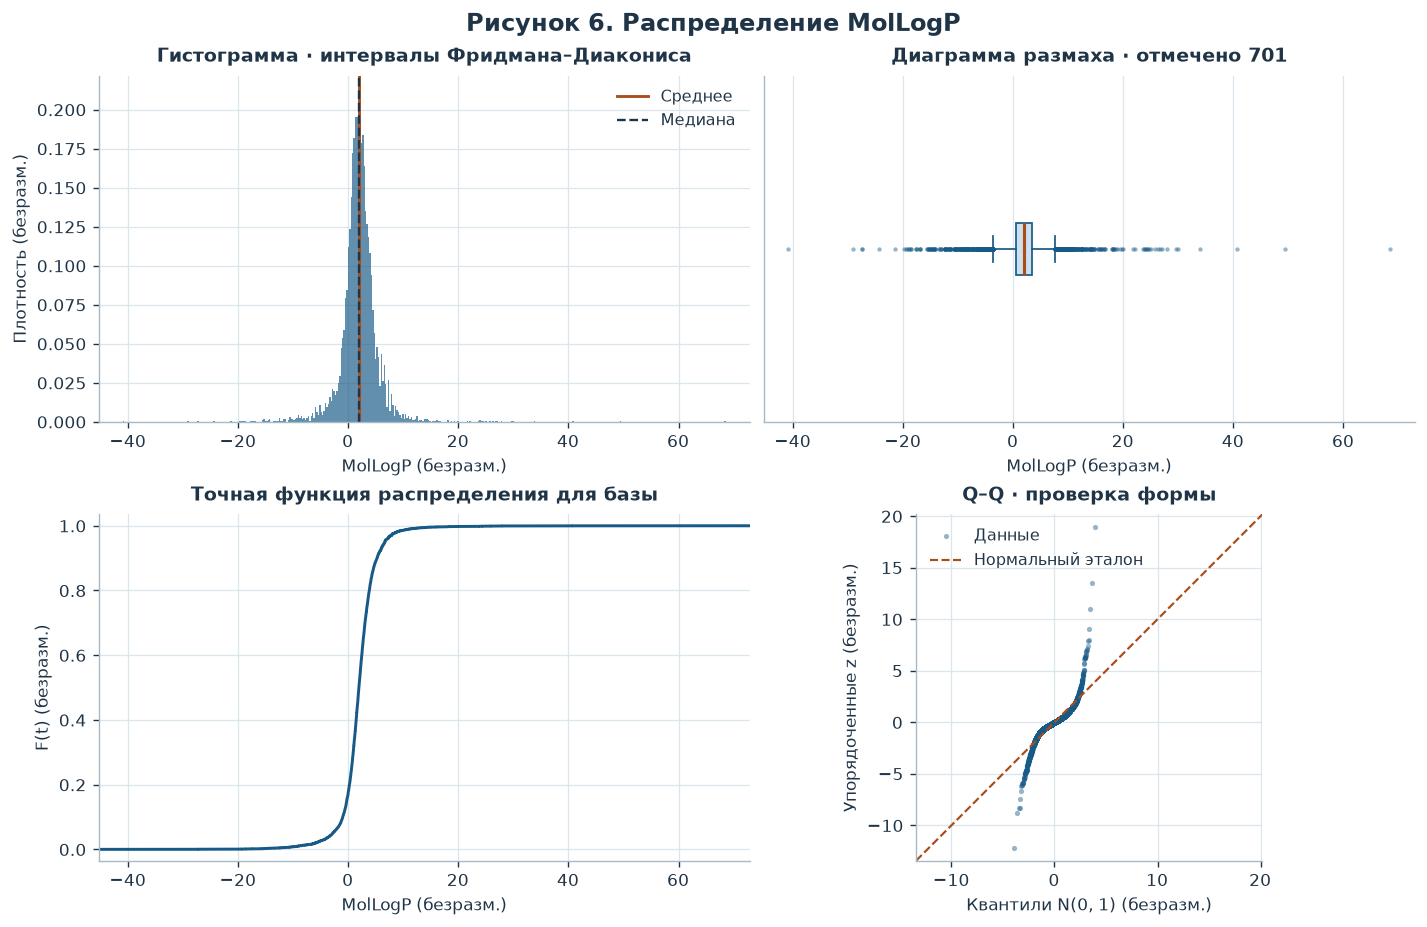

In [8]:
#@title Описательные статистики и графики: MolLogP { display-mode: "form" }
eda("MolLogP", 6)

<a id="logp-est" name="logp-est"></a>

### 1.3.3 Independence & Estimations

Оценки рассчитаны теми же способами и по тем же строкам, что для первых двух признаков. Почти одинаковые среднее и медиана всей базы не устраняют влияния крайних значений на дисперсию. Связи с двумя другими признаками разбираются в [разделе 1.4](#lab01-hypotheses).

,Объём,Уникальных соединений,"Среднее, безразм.","Дисперсия, безразм.","Сдвиг среднего, безразм.","Станд. ошибка, безразм."
Отбор,,,,,,
С возвращением,500,484,2.1745,23.9669,0.1953,0.1573
Без возвращения,500,500,1.8385,10.6140,-0.1406,0.1533
Вся база,9982,9982,1.9792,12.3732,0.0000,—


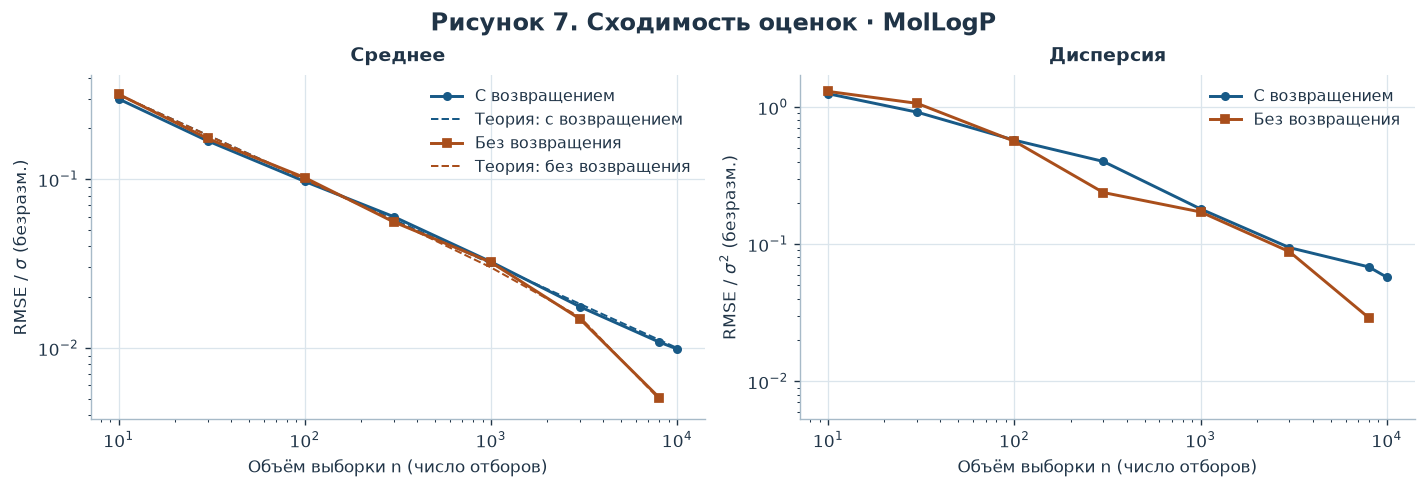

In [9]:
#@title Выборочные оценки и сходимость: MolLogP { display-mode: "form" }
comparison("MolLogP", 7)

<a id="lab01-hypotheses" name="lab01-hypotheses"></a>

## 1.4 Зависимость и проверка гипотез

[К оглавлению](#lab01-toc)

<a id="lab01-finite" name="lab01-finite"></a>

### 1.4.1 Проверка независимости в конечной совокупности

Для каждой пары обозначим через \\(A\\) и \\(B\\) события «соответствующий признак не выше своей медианы по базе». Считаем числа строк \\(n_A\\), \\(n_B\\) и \\(n_{AB}\\). Для независимых признаков равенство вероятностей должно выполняться для любых порогов, поэтому достаточно одного контрпримера. Сравниваем целые числа, чтобы не спутать расхождение с погрешностью округления.

\\[
\Pr(A\cap B)=\Pr(A)\Pr(B)
\quad\Longleftrightarrow\quad
Nn_{AB}=n_A n_B.
\\]

Диаграммы ниже показывают все наблюдения. Цвет кодирует число строк в шестиграннике по общей логарифмической шкале; оси самих признаков линейные. Коэффициенты Пирсона и Спирмена описывают линейную и монотонную связь соответственно. Знак и величина коэффициента не говорят о причинности.

,n(A),n(B),n(A ∩ B),P(A ∩ B),P(A)·P(B),Равенство выполнено,Пирсон,Спирмен
Пара,,,,,,,,
LogS / MolWt,4991,4993,1465,0.1468,0.2501,False,-0.3680,-0.5386
LogS / MolLogP,4991,4991,1018,0.1020,0.2500,False,-0.6086,-0.7398
MolWt / MolLogP,4993,4991,3296,0.3302,0.2501,False,0.2745,0.4216


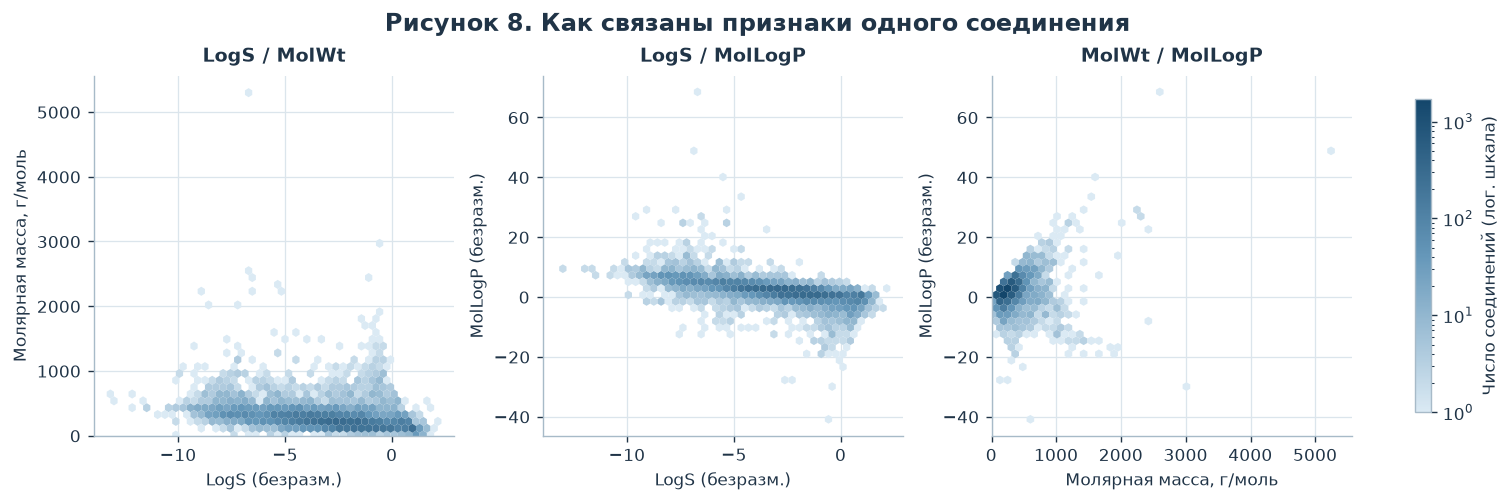

In [10]:
#@title Точный контрпример, корреляции и диаграммы связей { display-mode: "form" }
pairs = list(combinations(FEATURES, 2))
events = data.le(data.median())
dep_rows = []
for left, right in pairs:
    a, b = int(events[left].sum()), int(events[right].sum())
    ab = int((events[left] & events[right]).sum())
    dep_rows.append({
        "Пара": f"{left} / {right}", "n(A)": a, "n(B)": b, "n(A ∩ B)": ab,
        "P(A ∩ B)": ab / N, "P(A)·P(B)": a * b / N**2,
        "Равенство выполнено": N * ab == a * b,
        "Пирсон": stats.pearsonr(data[left], data[right]).statistic,
        "Спирмен": stats.spearmanr(data[left], data[right]).statistic,
    })
dependence = pd.DataFrame(dep_rows).set_index("Пара")
display(dependence.round(4))

cmap = LinearSegmentedColormap.from_list("aqsol-blue", ["#dbeaf4", "#6597b9", "#13466b"])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.9), layout="constrained")
fig.suptitle("Рисунок 8. Как связаны признаки одного соединения", fontsize=14, fontweight="bold")
hexbins = []
for axis, (left, right) in zip(ax, pairs):
    h = axis.hexbin(data[left], data[right], gridsize=45, mincnt=1, cmap=cmap, linewidths=0)
    assert h.get_array().sum() == N
    hexbins.append(h)
    axis.set(title=f"{left} / {right}", xlabel=LABEL[left], ylabel=LABEL[right])
    if left == "MolWt":
        axis.set_xlim(left=0)
    if right == "MolWt":
        axis.set_ylim(bottom=0)
shared = LogNorm(vmin=1, vmax=max(h.get_array().max() for h in hexbins))
for h in hexbins:
    h.set_norm(shared)
fig.colorbar(hexbins[0], ax=ax, label="Число соединений (лог. шкала)", shrink=.87)
show(fig)

<a id="lab01-test" name="lab01-test"></a>

### 1.4.2 Перестановочная проверка на выборке

Отдельно проверяем, видна ли зависимость по выборке из \\(n=500\\) независимых отборов с возвращением. Для каждой пары \\(H_0\\): признаки независимы в выбранной совокупности, поэтому вторую координату можно переставлять между строками без изменения совместного закона. \\(H_1\\): независимость нарушена. Статистика \\(\lvert r\rvert\\) чувствительна прежде всего к связи, проявляющейся в линейной корреляции; неотклонение не доказывало бы независимость. Модули нужны для двусторонней проверки.

Для каждой пары делаем \\(R=9999\\) случайных перестановок и сравниваем их корреляции \\(r_b^{*}\\) с наблюдаемой \\(r_{\mathrm{obs}}\\). Применяем поправку Бонферрони для трёх пар и сравниваем скорректированное значение с уровнем \\(\alpha=0.05\\).

\\[
p=\frac{1+\sum_{b=1}^{R}\mathbf{1}\{\lvert r_b^{*}\rvert\geq\lvert r_{\mathrm{obs}}\rvert\}}{R+1},
\qquad p_{\mathrm{adj}}=\min(1,3p).
\\]

In [11]:
#@title Перестановочный тест: три пары, поправка Бонферрони { display-mode: "form" }
R, alpha = 9999, .05
trial = data.iloc[rng_test.choice(N, size=500, replace=True)]
test_rows = []
for left, right in pairs:
    x, y = trial[left].to_numpy(), trial[right].to_numpy()
    x, y = x - x.mean(), y - y.mean()
    divisor = np.linalg.norm(x) * np.linalg.norm(y)
    r_obs = float(x @ y / divisor)
    exceed = sum(abs(x @ rng_perm.permutation(y) / divisor) >= abs(r_obs) - 1e-14
                 for _ in range(R))
    p = (1 + exceed) / (R + 1)
    adjusted = min(1, len(pairs) * p)
    test_rows.append({"Пара": f"{left} / {right}", "r в выборке": r_obs,
                      "Не менее экстремальных": exceed, "p": p, "p с поправкой": adjusted,
                      "Решение при α = 0,05": "Отклоняем H₀" if adjusted <= alpha else "Не отклоняем H₀"})
tests = pd.DataFrame(test_rows).set_index("Пара")
assert tests["p"].between(1 / (R + 1), 1).all()
display(tests.round(5))

,r в выборке,Не менее экстремальных,p,p с поправкой,"Решение при α = 0,05"
Пара,,,,,
LogS / MolWt,-0.39207,0,0.0001,0.0003,Отклоняем H₀
LogS / MolLogP,-0.68894,0,0.0001,0.0003,Отклоняем H₀
MolWt / MolLogP,0.35285,0,0.0001,0.0003,Отклоняем H₀


<a id="lab01-resume" name="lab01-resume"></a>

## 1.5 Lab resume

[К оглавлению](#lab01-toc)

<a id="lab01-findings" name="lab01-findings"></a>

### 1.5.1 Выводы

- **Распределения.** В AqSolDB у LogS левый хвост, а у MolWt выраженный правый. Логарифмирование массы сделало её распределение более симметричным, но не убрало отклонения в хвостах. Для MolLogP близость среднего и медианы скрывает редкие крайние значения. Простая стандартизация ни в одном случае не заменяет анализ формы.
- **Выборочные оценки.** При отборе с возвращением из 500 выборочных строк только 484 оказались разными. Стандартная ошибка среднего без возвращения ниже для всех признаков, но в конкретной выборке среднее LogS оказалось дальше от параметра базы. Это не противоречие: стандартная ошибка описывает разброс по повторным отборам, а не гарантирует точность каждого отбора. В моделировании ошибки в целом убывают с ростом объёма; при полном охвате без возвращения они равны нулю.
- **Связи.** В базе все три пары зависимы: для каждой пары медианные события дают точный контрпример к независимости. В выборке перестановочный тест тоже отклонил независимость для всех трёх пар после поправки Бонферрони; \\(p_{\mathrm{adj}}=0.0003\\) в каждой проверке. Это нижняя граница скорректированного значения для использованного числа случайных перестановок. Наиболее выраженная линейная связь в базе — между LogS и MolLogP (\\(r=-0.609\\)): у более липофильных соединений в AqSolDB растворимость обычно ниже. Это не доказывает причинность и не позволяет переносить результат за пределы базы.

In [12]:
#@title Сводная таблица результата { display-mode: "form" }
out = pd.DataFrame({
    "Единица исходного признака": pd.Series(UNIT), "Среднее базы": mu,
    "Медиана базы": data.median(), "Асимметрия": {c: eda_metrics[c]["skew"] for c in FEATURES},
    "Эксцесс": {c: eda_metrics[c]["excess"] for c in FEATURES},
})
wr = mc[mc["Отбор"].eq(methods[True])]
for n in (min(sizes), N):
    for key, title in (("mean_rmse", "RMSE среднего / σ"), ("var_rmse", "RMSE дисперсии / σ²")):
        out[f"{title}, n={n}"] = wr[wr["n"].eq(n)].set_index("Признак")[key]
display(out.round(4))
print("Ошибка переписи без возвращения: ноль для среднего и дисперсии всех трёх признаков.")
print("После поправки Бонферрони отвергнуто гипотез независимости:",
      int((tests["p с поправкой"] <= alpha).sum()), "из", len(pairs))

,Единица исходного признака,Среднее базы,Медиана базы,Асимметрия,Эксцесс,"RMSE среднего / σ, n=10","RMSE дисперсии / σ², n=10","RMSE среднего / σ, n=9982","RMSE дисперсии / σ², n=9982"
LogS,безразм.,-2.8899,-2.6182,-0.5516,-0.0600,0.3022,0.4476,0.0100,0.0139
MolWt,г/моль,266.6659,228.6820,5.4938,80.9231,0.3077,1.3043,0.0098,0.0919
MolLogP,безразм.,1.9792,1.9492,0.7182,29.5092,0.2987,1.2499,0.0099,0.0575


Ошибка переписи без возвращения: ноль для среднего и дисперсии всех трёх признаков.
После поправки Бонферрони отвергнуто гипотез независимости: 3 из 3


<a id="lab01-criteria" name="lab01-criteria"></a>

### 1.5.2 cat_mark_table

В таблице отмечены выполненные требования. Числовые коэффициенты не назначены: в условии для КТвД не приведены веса.

| cat_id | notebook_link | coeff | comment |
|:---|:---|:---:|:---|
| КТвД-01 | [Структура исследования](#lab01-toc) | — | Общие методы, три вложенных блока признаков, общая проверка и выводы. |
| КТвД-02 | [Индексы разделов](#lab01-data) | — | Сквозная нумерация разделов и подразделов. |
| КТвД-03 | [Навигация](#lab01-toc) | — | Оглавление, возврат к нему и переходы к общему анализу связей. |
| КТвД-04 | [Скрытие кода](#lab01-toc) | — | Технические ячейки свёрнуты, результаты и формулы видны. |
| КТвД-05 | [Масштабы и единицы](#molwt-eda) | — | Подписаны шкалы и единицы; нулевая ошибка не нанесена на логарифмическую ось. |
| КТвД-06 | [Оформление графиков](#logs-eda) | — | Единый шрифт, палитра, нумерация и обозначения. |
| КТвД-07 | [Формулы LaTeX](#lab01-methods) | — | Единые обозначения вероятностей, моментов, выборочных оценок и критериев. |
| Lab01-S1 | [Итоги первого спринта](#lab01-resume) | — | Три случайные величины, EDA, нормализация, отбор двух типов, сходимость, гипотезы. |

[К оглавлению](#lab01-toc)